# Modelado y Evaluación de Clasificación: Churn de clientes

**Objetivo:** entrenar un modelo de clasificación binaria que prediga si un cliente abandonará el servicio (`Churn`) y evaluarlo con Accuracy, Precision, Recall, F1-Score y Matriz de Confusión.

**Dataset:** Telco Customer Churn (IBM), 7.043 clientes de una empresa de telecomunicaciones.

## 1. Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42

## 2. Carga y exploración de datos

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` viene como texto porque hay valores vacíos (clientes nuevos con `tenure = 0`). Lo convertimos a numérico y eliminamos esas pocas filas. También descartamos `customerID`, que es solo un identificador.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulos en TotalCharges:", df["TotalCharges"].isna().sum())

df = df.dropna(subset=["TotalCharges"]).drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)   # 1 = abandona, 0 = se queda

print("Filas finales:", len(df))
print("\nDistribución de la variable objetivo:")
print(df["Churn"].value_counts(normalize=True).round(3))

Nulos en TotalCharges: 11
Filas finales: 7032

Distribución de la variable objetivo:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


Las clases están **desbalanceadas** (~73% se queda, ~27% abandona). Por eso el Accuracy por sí solo puede engañar: un modelo que siempre prediga "no abandona" tendría ~73% de accuracy y no detectaría a ningún cliente en riesgo.

## 3. División en entrenamiento y prueba (80/20)

In [5]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de churn en train:", y_train.mean().round(3))
print("Proporción de churn en test: ", y_test.mean().round(3))

Train: (5625, 19) | Test: (1407, 19)
Proporción de churn en train: 0.266
Proporción de churn en test:  0.266


Se usa `stratify=y` para mantener la misma proporción de churn en ambos conjuntos.

## 4. Entrenamiento del modelo (Logistic Regression)

In [6]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

modelo = Pipeline([
    ("prep", preprocesador),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=RANDOM_STATE)),
])

modelo.fit(X_train, y_train)
print("Modelo entrenado.")

Modelo entrenado.


Se usa un `Pipeline` para que el escalado y la codificación se ajusten **solo con los datos de entrenamiento** (evita *data leakage*). `class_weight="balanced"` compensa el desbalance de clases dándole más peso a los clientes que abandonan.

## 5. Evaluación en el conjunto de prueba

In [7]:
y_pred = modelo.predict(X_test)

metricas = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-Score":  f1_score(y_test, y_pred),
}
pd.DataFrame(metricas, index=["Valor"]).T.round(4)

,Valor
Accuracy,0.7257
Precision,0.4901
Recall,0.7968
F1-Score,0.6069


Verdaderos negativos (TN): 723
Falsos positivos     (FP): 310
Falsos negativos     (FN): 76
Verdaderos positivos (TP): 298


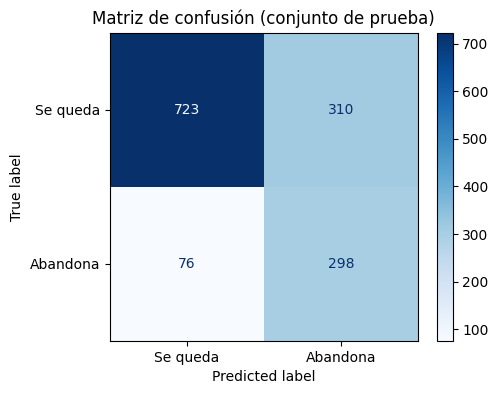

In [8]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos (TN): {tn}")
print(f"Falsos positivos     (FP): {fp}")
print(f"Falsos negativos     (FN): {fn}")
print(f"Verdaderos positivos (TP): {tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Se queda", "Abandona"]).plot(
    ax=ax, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusión (conjunto de prueba)")
plt.show()

In [9]:
print(classification_report(y_test, y_pred, target_names=["Se queda", "Abandona"]))

              precision    recall  f1-score   support

    Se queda       0.90      0.70      0.79      1033
    Abandona       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



## 6. Interpretación: ¿qué métrica es la más importante?

### La métrica más importante para Churn es el **Recall** (sensibilidad)

**Qué mide:** de todos los clientes que *realmente* abandonan, qué porcentaje logra detectar el modelo:

$$Recall = \frac{TP}{TP + FN}$$

**Por qué, según el costo de los errores:**

| Error | Qué significa | Costo para la empresa |
|---|---|---|
| **Falso negativo (FN)** | El modelo dice "se queda" pero el cliente se va | **Alto.** Se pierde el cliente y sus ingresos recurrentes. Además, captar un cliente nuevo suele costar mucho más que retener uno existente. Y como no fue detectado, nadie intervino a tiempo. |
| **Falso positivo (FP)** | El modelo dice "se va" pero el cliente se quedaba | **Bajo.** Se le ofrece una promoción o un llamado de retención a alguien que no lo necesitaba. Es un gasto acotado. |

Como un FN cuesta bastante más que un FP, conviene **minimizar los falsos negativos**, es decir, **maximizar el Recall**: preferimos contactar de más a clientes que quizás no se iban antes que dejar escapar a los que sí se van.

**Por qué no el Accuracy:** con ~73% de clientes que se quedan, un modelo "ingenuo" que nunca prediga abandono tendría ~73% de accuracy y 0% de recall. Sería inútil para el negocio.

**Matiz importante:** maximizar solo el Recall llevaría a marcar a todos como "abandona". Por eso se lo acompaña con la **Precision** y el **F1-Score**, que controlan que no se disparen los falsos positivos (y con ellos el costo de las campañas de retención). En la práctica, el umbral de decisión se ajusta según cuánto cuesta una campaña frente al valor de un cliente retenido.

## 7. Conclusiones

Ver los valores obtenidos en la sección 5 y el resumen en el `README.md`. Posibles mejoras: probar Random Forest o Gradient Boosting, ajustar el umbral de clasificación con la curva Precision-Recall, y usar validación cruzada para ajustar hiperparámetros.